> STATUS: ATUAL — execução final COM, BEST época 3.
> Revisão editorial em 30/10/2026: somente apresentação de resultados existentes; este notebook não foi reexecutado nesta revisão.
> Consulte o [guia oficial](../../../GUIA_NOTEBOOKS_RESULTADOS.md). Os notebooks 03/04 contêm chamadas de inferência; seus outputs estão preservados e não devem ser reexecutados nesta etapa editorial.


In [1]:
# [celula injetada pelo executor] redireciona config para a politica shared-extrasystoles-bbb-v1
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import config
config.CLASSIFICATION_POLICY = "shared-extrasystoles-bbb-v1"
config.MITBIH_PROCESSED_FILE = config.PROCESSED_DIR / "mitbih_shared-extrasystoles-bbb-v1.npz"
config.LUDB_PROCESSED_FILE = config.PROCESSED_DIR / "ludb_shared-extrasystoles-bbb-v1.npz"


# 01 — Exploração do MIT-BIH Arrhythmia Database

Inspeção visual dos sinais e das anotações, e verificação do dataset gerado por
`src/preprocess_mitbih.py`.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import sys
from pathlib import Path

# O codigo do projeto vive em src/ (nao ha pacote instalavel).
sys.path.insert(0, str(Path.cwd().parent / "src"))
import config
import beat_io

## Verificação do dataset processado

Os artefatos desta execução já estão presentes no pacote. Não é necessário executar o pipeline para consultar estes outputs; veja o guia oficial.

In [3]:
dados = beat_io.load_beat_dataset(config.MITBIH_PROCESSED_FILE)

X, y = dados["series"], dados["labels"]
print(f"series    : {X.shape} {X.dtype}")
print(f"labels    : {np.bincount(y)} (0 = não-arritmia, 1 = arritmia)")
print(f"pacientes : {len(np.unique(dados['pacientes']))} registros")
print(f"média/desvio por batimento: {X.mean(axis=1).mean():.2e} / {X.std(axis=1).mean():.4f}")

series    : (99442, 234) float32
labels    : [74517 24925] (0 = não-arritmia, 1 = arritmia)
pacientes : 44 registros
média/desvio por batimento: -1.36e-09 / 1.0000


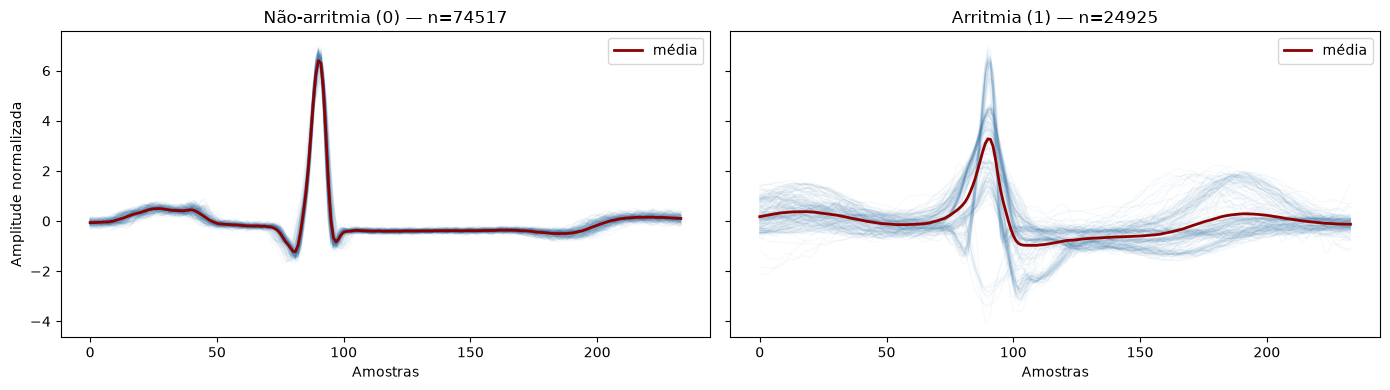

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

for ax, classe, titulo in zip(axes, [0, 1], ["Não-arritmia (0)", "Arritmia (1)"]):
    amostras = X[y == classe][:200]
    ax.plot(amostras.T, color="steelblue", alpha=0.05, linewidth=0.8)
    ax.plot(amostras.mean(axis=0), color="darkred", linewidth=2, label="média")
    ax.set_title(f"{titulo} — n={int((y == classe).sum())}")
    ax.set_xlabel("Amostras")
    ax.legend()

axes[0].set_ylabel("Amplitude normalizada")
fig.tight_layout()
plt.show()

## Amostra individual: batimento normal vs. arrítmico

Um batimento de cada classe, com o símbolo original do MIT-BIH, o registro de
origem e a posição do pico R, além dos metadados salvos junto ao dataset.

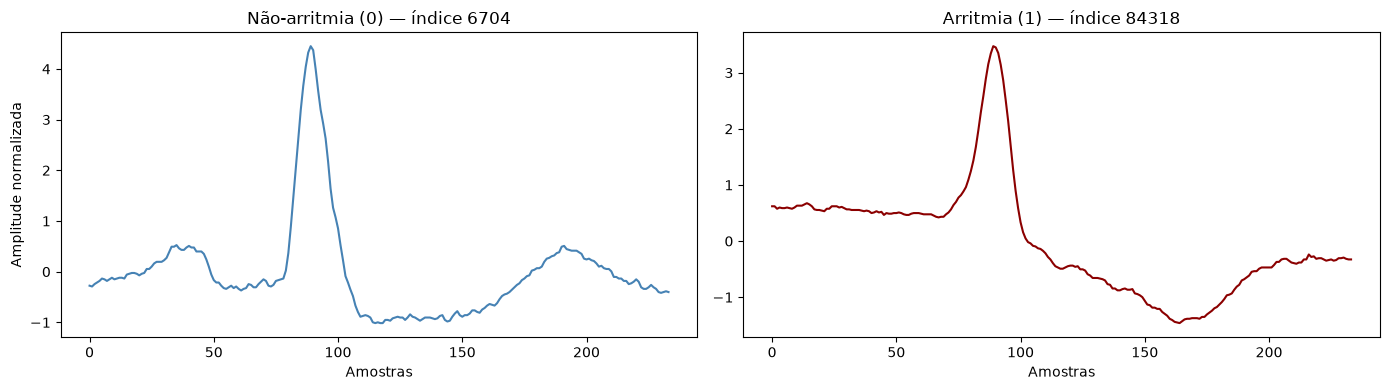

--- Batimento Normal (índice 6704) ---
  símbolo original : np.str_('N')
  classe binária   : 0 (não-arritmia)
  paciente (registro) : 105
  posição do pico R (sinal original): 126467

--- Batimento Arrítmico (índice 84318) ---
  símbolo original : np.str_('V')
  classe binária   : 1 (arritmia)
  paciente (registro) : 223
  posição do pico R (sinal original): 225997

--- Metadados do dataset ---
  dataset: mit-bih-arrhythmia
  dataset_version: 1.0.0
  fs_hz: 360
  records: ['100', '101', '103', '105', '106', '108', '109', '111', '112', '113', '114', '115', '116', '117', '118', '119', '121', '122', '123', '124', '200', '201', '202', '203', '205', '207', '208', '209', '210', '212', '213', '214', '215', '219', '220', '221', '222', '223', '228', '230', '231', '232', '233', '234']
  lead: MLII
  window_left: 90
  window_right: 144
  window_size: 234
  non_beat_symbols: ['!', '"', '+', '[', ']', 'x', '|', '~']
  negative_symbols: ['N']
  normalization: z-score per beat
  classification_polic

In [5]:
rng = np.random.default_rng(42)

idx_normal = rng.choice(np.flatnonzero(y == 0))
# escolher arritmias que tenha o simbolo V
idx_arritmico = rng.choice(np.flatnonzero((y == 1) & (dados["simbolos"] == "V")))

r_peaks = dados.get("r_peaks")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, idx, titulo, cor in [
    (axes[0], idx_normal, "Não-arritmia (0)", "steelblue"),
    (axes[1], idx_arritmico, "Arritmia (1)", "darkred"),
]:
    ax.plot(X[idx], color=cor, linewidth=1.5)
    ax.set_title(f"{titulo} — índice {idx}")
    ax.set_xlabel("Amostras")

axes[0].set_ylabel("Amplitude normalizada")
fig.tight_layout()
plt.show()

for nome, idx in [("Normal", idx_normal), ("Arrítmico", idx_arritmico)]:
    print(f"--- Batimento {nome} (índice {idx}) ---")
    print(f"  símbolo original : {dados['simbolos'][idx]!r}")
    print(f"  classe binária   : {y[idx]} ({'não-arritmia' if y[idx] == 0 else 'arritmia'})")
    print(f"  paciente (registro) : {dados['pacientes'][idx]}")
    if r_peaks is not None:
        print(f"  posição do pico R (sinal original): {r_peaks[idx]}")
    print()

print("--- Metadados do dataset ---")
for chave, valor in dados["metadata"].items():
    print(f"  {chave}: {valor}")